# 01 · Explore the dataset

A guided tour of what the pipeline produced, from raw prices to the exact windows the model will see.

Run `tickercast all` first so `data/` exists. Run cells top to bottom (Shift+Enter).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
for f in sorted(DATA.rglob("*.parquet")):
    print(f"{f.relative_to(ROOT)!s:40s} {f.stat().st_size / 1e6:8.1f} MB")

Matplotlib is building the font cache; this may take a moment.


data/interim/features.parquet               378.0 MB
data/processed/dataset.parquet              377.1 MB
data/raw/macro.parquet                        0.2 MB
data/raw/market.parquet                       2.0 MB
data/raw/prices.parquet                      89.9 MB
data/raw/universe.parquet                     0.0 MB


## 1. Raw data: what we downloaded

### Universe: which stocks

In [2]:
universe = pd.read_parquet(DATA / "raw/universe.parquet")
print(len(universe), "stocks")
universe.head(10)

503 stocks


,ticker,name,sector,sub_industry,date_added
0,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,2000-06-05
1,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals",1982-11-30
2,ABBV,AbbVie,Health Care,Biotechnology,2012-12-31
3,ABNB,Airbnb,Consumer Discretionary,"Hotels, Resorts & Cruise Lines",2023-09-18
4,ABT,Abbott Laboratories,Health Care,Health Care Equipment,1957-03-04
5,ACGL,Arch Capital Group,Financials,Property & Casualty Insurance,2022-11-01
6,ACN,Accenture,Information Technology,IT Consulting & Other Services,2011-07-06
7,ADBE,Adobe Inc.,Information Technology,Application Software,1997-05-05
8,ADI,Analog Devices,Information Technology,Semiconductors,1999-10-12
9,ADM,Archer Daniels Midland,Consumer Staples,Agricultural Products & Services,1957-03-04


In [3]:
universe["sector"].value_counts()

sector
Industrials               83
Financials                76
Information Technology    75
Health Care               60
Consumer Discretionary    47
Consumer Staples          34
Utilities                 31
Real Estate               30
Materials                 24
Communication Services    22
Energy                    21
Name: count, dtype: int64

### Prices: one row per stock per day (adjusted for splits and dividends)

In [4]:
prices = pd.read_parquet(DATA / "raw/prices.parquet")
print(f"{len(prices):,} rows, {prices['ticker'].nunique()} stocks, {prices['date'].min().date()} -> {prices['date'].max().date()}")
aapl_raw = prices[prices["ticker"] == "AAPL"]
aapl_raw.tail()

2,488,915 rows, 503 stocks, 2005-01-03 -> 2026-10-09


,date,ticker,open,high,low,close,volume
10949,2026-10-05,AAPL,332.820007,336.209991,331.649994,332.890015,34400900.0
10950,2026-10-06,AAPL,332.279999,334.380005,330.619995,333.630005,30449000.0
10951,2026-10-07,AAPL,336.959991,338.670013,332.779999,336.670013,34147900.0
10952,2026-10-08,AAPL,336.820007,341.570007,335.899994,340.420013,35332400.0
10953,2026-10-09,AAPL,331.700012,338.609985,330.700012,336.640015,37855000.0


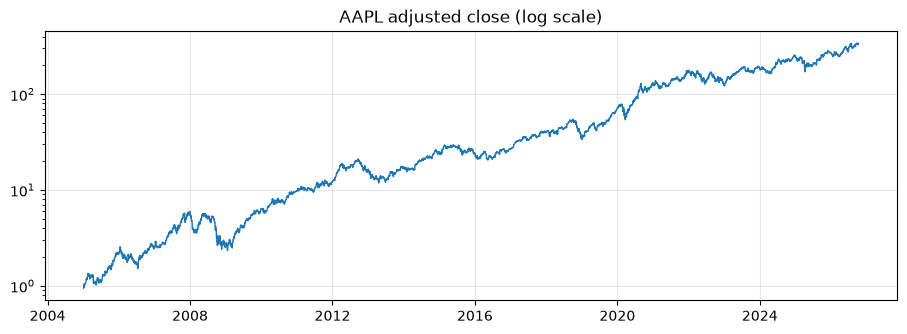

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(aapl_raw["date"], aapl_raw["close"], lw=1)
ax.set_yscale("log"); ax.set_title("AAPL adjusted close (log scale)"); ax.grid(alpha=0.3)
plt.show()

### Market benchmarks and macro

In [6]:
market = pd.read_parquet(DATA / "raw/market.parquet")
market.pivot(index="date", columns="ticker", values="close").tail()

ticker,GLD,QQQ,SOXX,SPY,TLT,USO,UUP,XLK,^VIX
date,,,,,,,,,
2026-10-05,379.549988,756.200012,589.510010,774.830017,77.110001,143.990005,28.990000,200.929993,15.52
2026-10-06,382.269989,759.659973,589.450012,779.090027,77.279999,144.910004,28.900000,202.000000,15.01
2026-10-07,375.880005,757.729980,582.820007,777.219971,77.150002,143.910004,29.040001,201.389999,15.08
2026-10-08,378.619995,747.580017,563.280029,773.929993,77.870003,147.580002,28.980000,197.779999,15.41
2026-10-09,384.579987,751.270020,559.400024,778.570007,77.980003,148.199997,29.020000,198.779999,14.84


In [7]:
macro_path = DATA / "raw/macro.parquet"
if macro_path.exists():
    macro = pd.read_parquet(macro_path)
    # obs_date = the period a number describes; available_date = when the public learned it
    display(macro[macro["series"] == "CPIAUCSL"].tail(6))
else:
    print("No macro data (FRED_API_KEY not set)")

,series,name,obs_date,value,available_date
30000,CPIAUCSL,cpi,2026-03-01,330.293,2026-04-10
30001,CPIAUCSL,cpi,2026-04-01,332.407,2026-05-12
30002,CPIAUCSL,cpi,2026-05-01,333.979,2026-06-10
30003,CPIAUCSL,cpi,2026-06-01,332.568,2026-07-14
30004,CPIAUCSL,cpi,2026-07-01,332.813,2026-08-12
30005,CPIAUCSL,cpi,2026-08-01,334.131,2026-09-11


## 2. Feature table: the real world as numbers

`data/interim/features.parquet`: one row per (stock, day). Inputs + targets, before scaling.
Docs: [docs/03_features.md](../docs/03_features.md).

In [8]:
feats = pd.read_parquet(DATA / "interim/features.parquet")
targets = [c for c in feats.columns if c.startswith(("fwd_", "label_"))]
inputs = [c for c in feats.columns if c not in ["date", "ticker", "sector", *targets]]
print(f"{len(feats):,} rows · {len(inputs)} input features · {len(targets)} target columns")
print("\nInputs:", ", ".join(inputs))
print("\nTargets:", ", ".join(targets))

2,357,926 rows · 66 input features · 8 target columns

Inputs: ret_1d, ret_5d, ret_20d, ret_60d, vol_20d, vol_60d, volume_ratio, rsi, ma_dist_50, ma_dist_200, hl_range, gap, drawdown_252, cs_rank_ret_5d, cs_rank_ret_20d, cs_rank_ret_60d, cs_rank_vol_20d, cs_rank_volume_ratio, sector_ret_1d, rel_sector_ret_1d, sector_ret_5d, rel_sector_ret_5d, breadth, gld_ret_1d, gld_ret_5d, qqq_ret_1d, qqq_ret_5d, semis_ret_1d, semis_ret_5d, spy_ret_1d, spy_ret_5d, tlt_ret_1d, tlt_ret_5d, oil_ret_1d, oil_ret_5d, usd_ret_1d, usd_ret_5d, tech_ret_1d, tech_ret_5d, spy_vol_20d, spy_drawdown_252, vix_log, vix_chg_1d, vix_z_60, rel_spy_ret_1d, beta_spy, yield_10y, yield_10y_chg_20d, yield_2y, yield_2y_chg_20d, curve_10y2y, curve_10y2y_chg_20d, credit_spread, credit_spread_chg_20d, fed_funds, fed_funds_chg_20d, cpi_yoy, unemployment, unemployment_chg_3m, dow_sin, dow_cos, month_sin, month_cos, days_to_quarter_end, is_q4, opex_week

Targets: fwd_ret_1d, label_up_1d, fwd_excess_1d, label_outperform_1d, fwd_ret

### One week of Apple, a few key columns

The week of Apple's May 2024 earnings + $110B buyback (reported after the close on May 2).

In [9]:
cols = ["date", "ret_1d", "gap", "volume_ratio", "rel_sector_ret_1d", "spy_ret_1d", "vix_log", "breadth", "fwd_ret_1d", "label_up_1d"]
aapl = feats[feats["ticker"] == "AAPL"]
week = aapl[(aapl["date"] >= "2024-04-29") & (aapl["date"] <= "2024-05-07")][cols]
week.style.format(precision=4).background_gradient(subset=["ret_1d", "gap", "volume_ratio"], cmap="RdYlGn")

,date,ret_1d,gap,volume_ratio,rel_sector_ret_1d,spy_ret_1d,vix_log,breadth,fwd_ret_1d,label_up_1d
9939,2024-04-29 00:00:00,0.0245,0.0238,0.1842,0.0193,0.0035,2.6858,0.2163,-0.0184,0.0000
9940,2024-04-30 00:00:00,-0.0184,-0.0010,0.1364,-0.0002,-0.0160,2.7505,-0.3813,-0.0061,0.0000
9941,2024-05-01 00:00:00,-0.0061,-0.0044,-0.1350,0.0112,-0.0033,2.7337,-0.0151,0.0218,1.0000
9942,2024-05-02 00:00:00,0.0218,0.0188,0.4564,0.0083,0.0093,2.6865,0.2143,0.0581,1.0000
9943,2024-05-03 00:00:00,0.0581,0.0758,0.9093,0.0439,0.0123,2.6019,0.2445,-0.0091,0.0000
9944,2024-05-06 00:00:00,-0.0091,-0.0056,0.1474,-0.0252,0.0103,2.6019,0.2807,0.0038,1.0000
9945,2024-05-07 00:00:00,0.0038,0.0095,0.1057,0.0107,0.0011,2.5825,0.1338,0.0019,1.0000


### Every column for a single day (May 3, 2024)

In [10]:
aapl[aapl["date"] == "2024-05-03"].T.rename(columns=lambda _: "AAPL 2024-05-03")

,AAPL 2024-05-03
date,2024-05-03 00:00:00
ticker,AAPL
sector,Information Technology
ret_1d,0.058095
ret_5d,0.079888
...,...
label_outperform_1d,0.0
fwd_ret_5d,-0.000446
label_up_5d,0.0
fwd_excess_5d,-0.018951


### A few features over time

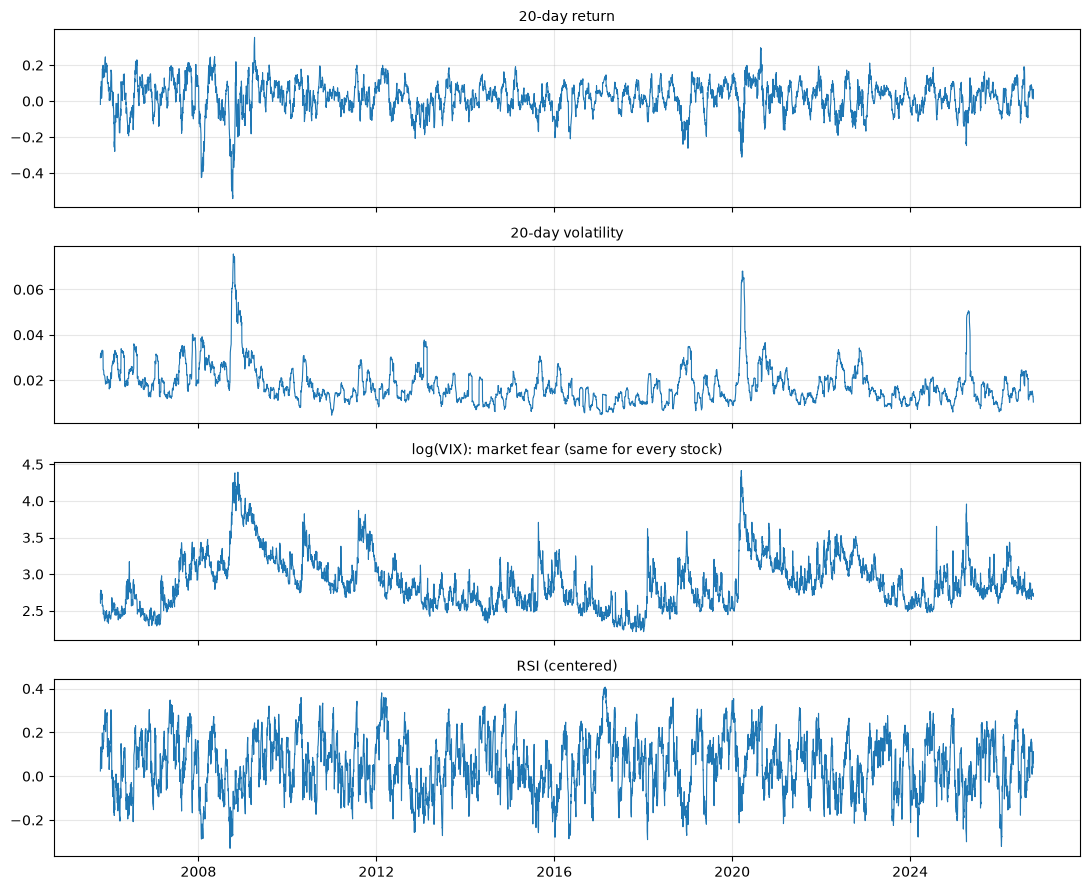

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, col, title in zip(axes, ["ret_20d", "vol_20d", "vix_log", "rsi"],
                          ["20-day return", "20-day volatility", "log(VIX): market fear (same for every stock)", "RSI (centered)"]):
    ax.plot(aapl["date"], aapl[col], lw=0.8); ax.set_title(title, fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Targets: how often did stocks go up the next day?

This is the "always up" baseline the model must beat.

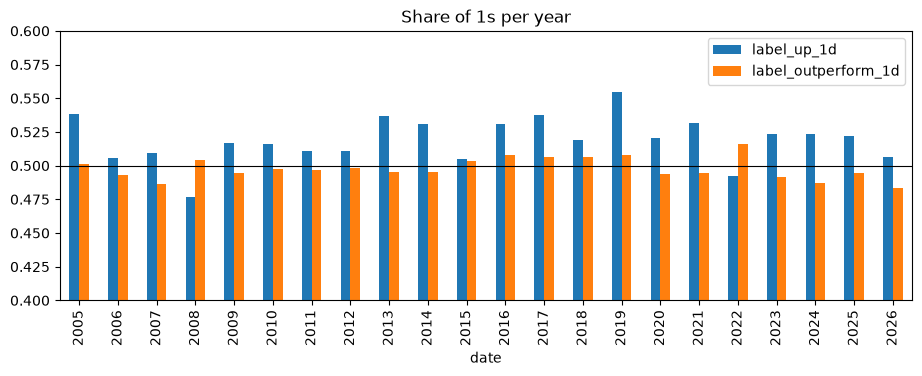

In [12]:
by_year = feats.groupby(feats["date"].dt.year)[["label_up_1d", "label_outperform_1d"]].mean()
ax = by_year.plot(kind="bar", figsize=(11, 3.5), title="Share of 1s per year")
ax.axhline(0.5, color="black", lw=0.8); ax.set_ylim(0.4, 0.6); plt.show()

## 3. Model-ready dataset: what the Transformer sees

`data/processed/dataset.parquet`: same rows, but features are **scaled** with training-period statistics
(mean 0, std 1, clipped to ±5), gaps filled with 0, plus `split`, `ticker_id`, `sector_id`.
Docs: [docs/06_model_input.md](../docs/06_model_input.md).

In [13]:
meta = json.loads((DATA / "processed/meta.json").read_text())
ds = pd.read_parquet(DATA / "processed/dataset.parquet", filters=[("ticker", "==", "AAPL")])
print("splits:", meta["splits"], "| window:", meta["window"], "| target:", meta["default_target"])
ds[ds["date"].between("2024-04-29", "2024-05-07")][["date", "split", "ticker_id", "sector_id", "ret_1d", "gap", "volume_ratio", "label_up_1d"]]

splits: {'train_end': '2019-12-31', 'val_end': '2021-12-31', 'embargo_days': 5} | window: 128 | target: label_up_1d


,date,split,ticker_id,sector_id,ret_1d,gap,volume_ratio,label_up_1d
4662,2024-04-29,test,1,7,1.132620,2.083535,0.643814,0.0
4663,2024-04-30,test,1,7,-0.890521,-0.108641,0.524341,0.0
4664,2024-05-01,test,1,7,-0.307549,-0.412824,-0.152927,1.0
4665,2024-05-02,test,1,7,1.004828,1.642827,1.323174,1.0
4666,2024-05-03,test,1,7,2.715049,5.000000,2.453614,0.0
4667,2024-05-06,test,1,7,-0.452793,-0.520915,0.551828,1.0
4668,2024-05-07,test,1,7,0.156724,0.822818,0.447868,1.0


In [14]:
all_splits = pd.read_parquet(DATA / "processed/dataset.parquet", columns=["date", "split"])
all_splits.groupby("split")["date"].agg(["min", "max", "count"])

,min,max,count
split,,,
embargo,2019-12-24,2021-12-31,4793
test,2022-01-03,2026-10-09,591256
train,2005-10-18,2019-12-23,1521727
val,2020-01-02,2021-12-23,240150


### One training sample: a 128-day window

Each sample is a (128 days × features) block plus a 0/1 label for the day after the window ends.
Below: the window ending on 2024-05-03 for AAPL. Each row of the image is a feature, each column a day.
The earnings jump is visible at the right edge.

588,876 test windows
x shape: (128, 66) | label: 0.0 | ticker: AAPL | sector: Information Technology


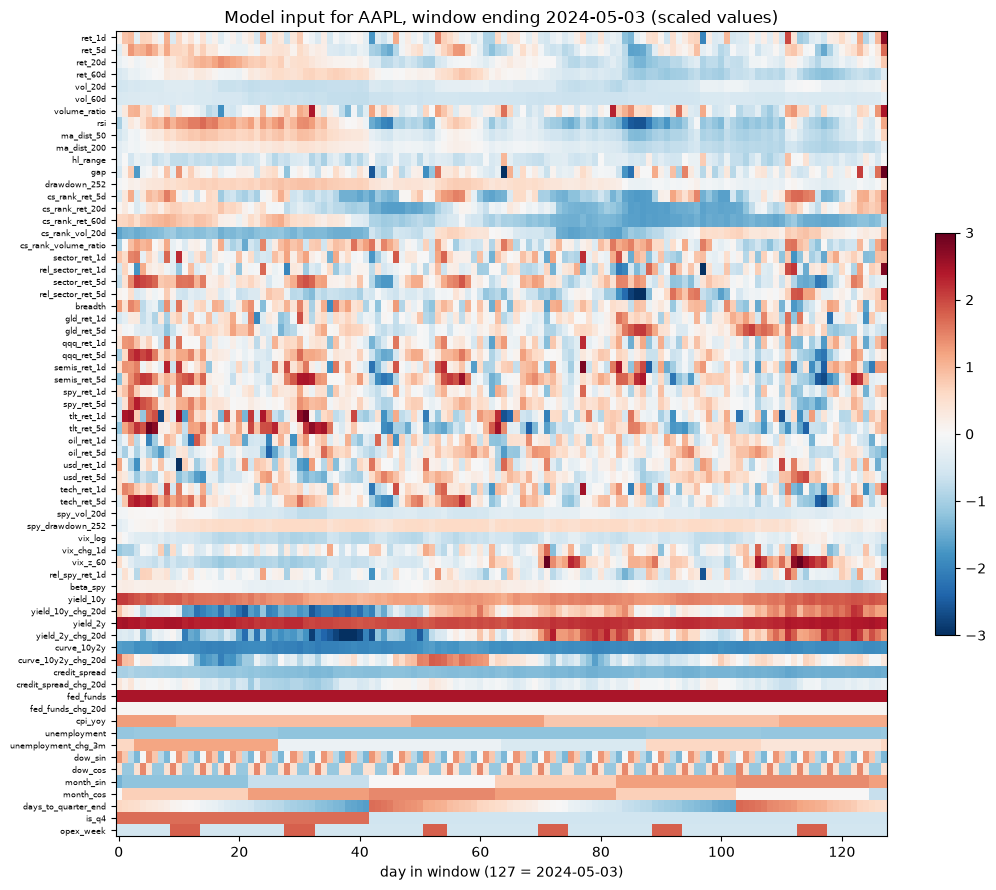

In [15]:
import sys; sys.path.insert(0, str(ROOT / "src"))
from tickercast.dataset.windows import WindowDataset

test = WindowDataset(DATA / "processed", split="test")
print(f"{len(test):,} test windows")
aapl_id = meta["tickers"].index("AAPL")
i = next(k for k, t in enumerate(test.ends) if test.ticker_id[t] == aapl_id and str(test.dates[t])[:10] == "2024-05-03")
x, y, tid, sid = test[i]
print("x shape:", x.shape, "| label:", y, "| ticker:", meta["tickers"][tid], "| sector:", meta["sectors"][sid])

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(x.T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax.set_yticks(range(len(test.features))); ax.set_yticklabels(test.features, fontsize=6)
ax.set_xlabel("day in window (127 = 2024-05-03)"); ax.set_title("Model input for AAPL, window ending 2024-05-03 (scaled values)")
plt.colorbar(im, ax=ax, shrink=0.5); plt.tight_layout(); plt.show()

## 4. Browse in a spreadsheet

Export any stock to CSV (opens in Excel or your IDE's table viewer):

```bash
tickercast sample --ticker AAPL --stage features      # or --stage raw / dataset
tickercast sample --ticker NVDA --start 2024-01-01
```
Files land in `data/samples/`.